
# Sales Performance Analysis

## 1. Project Overview

This project analyzes sales performance using Python, Pandas, Matplotlib, and PostgreSQL.

### Objectives
- Evaluate overall sales and profitability.
- Compare category and regional performance.
- Identify loss-making product subcategories.
- Analyze the relationship between discounts and profit margins.
- Develop data-driven business recommendations.

### Tools
- Python
- Pandas
- Matplotlib
- PostgreSQL
- Jupyter Notebook
- Power BI


In [2]:
import os

os.environ["PGPASSWORD"] = input("Enter your PostgreSQL password: ")

In [3]:

import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

PROJECT_ROOT = Path(r"D:\sales-performance-analysis")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from python.db_config import engine

print("Libraries imported successfully!")
print("Project root:", PROJECT_ROOT)


Libraries imported successfully!
Project root: D:\sales-performance-analysis


In [4]:
with engine.connect() as connection:
    total_rows = connection.execute(
        text("SELECT COUNT(*) FROM analytics.sales_clean")
    ).scalar()

print("Database connection successful!")
print(f"Total records available: {total_rows:,}")

Database connection successful!
Total records available: 10,194



## 2. Load the Dataset

We will retrieve the cleaned sales data from PostgreSQL and inspect its structure, dimensions, data types, and sample records before performing exploratory data analysis.


In [5]:

query = """
SELECT *
FROM analytics.sales_clean
"""

with engine.connect() as connection:
    df = pd.read_sql(query, connection)

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")


Dataset loaded successfully!
Number of rows: 10,194
Number of columns: 21


In [6]:

df.head()


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country_region,city,...,postal_code,region,product_id,category,sub_category,product_name,sales,quantity,discount,profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.45,2,0.2,5.55
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.54,2,0.8,-5.49
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.78,3,0.2,4.27
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.74,3,0.2,-64.77
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.54,3,0.2,4.88


In [7]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   row_id          10194 non-null  int64         
 1   order_id        10194 non-null  str           
 2   order_date      10194 non-null  datetime64[us]
 3   ship_date       10194 non-null  datetime64[us]
 4   ship_mode       10194 non-null  str           
 5   customer_id     10194 non-null  str           
 6   customer_name   10194 non-null  str           
 7   segment         10194 non-null  str           
 8   country_region  10194 non-null  str           
 9   city            10194 non-null  str           
 10  state_province  10194 non-null  str           
 11  postal_code     10194 non-null  str           
 12  region          10194 non-null  str           
 13  product_id      10194 non-null  str           
 14  category        10194 non-null  str           
 15  sub_category 

In [8]:

df.describe(include="all").T


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
row_id,10194.0,NaN,NaN,NaN,5097.5,1.0,2549.25,5097.5,7645.75,10194.0,2942.898656
order_id,10194,5111,US-2026-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,10194,NaN,NaN,NaN,2025-04-29 11:48:25.002943,2023-01-03 00:00:00,2024-05-14 00:00:00,2025-06-25 00:00:00,2026-05-14 00:00:00,2026-12-30 00:00:00,NaN
ship_date,10194,NaN,NaN,NaN,2025-05-03 10:52:45.626839,2023-01-07 00:00:00,2024-05-19 00:00:00,2025-06-28 00:00:00,2026-05-18 00:00:00,2027-01-05 00:00:00,NaN
ship_mode,10194,4,Standard Class,6120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,10194,804,WB-21850,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,10194,800,William Brown,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segment,10194,3,Consumer,5281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_region,10194,2,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,10194,542,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN



## 3. Data Quality Assessment

Before analyzing sales performance, we will check for missing values, duplicate records, invalid numerical values, and date inconsistencies. These checks help establish the reliability of the dataset.


In [9]:

# 3.1 Missing values
missing_values = df.isnull().sum()

missing_summary = (
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

if missing_summary.empty:
    print("No missing values found.")
else:
    display(missing_summary.to_frame("missing_count"))

# 3.2 Duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# 3.3 Duplicate row identifiers
print("Duplicate row IDs:", df["row_id"].duplicated().sum())

# 3.4 Duplicate order-product combinations
print(
    "Duplicate order-product combinations:",
    df.duplicated(subset=["order_id", "product_id"]).sum()
)


No missing values found.
Exact duplicate rows: 0
Duplicate row IDs: 0
Duplicate order-product combinations: 11


In [10]:

# Check values that may need investigation
print("Sales <= 0:", (df["sales"] <= 0).sum())
print("Quantity <= 0:", (df["quantity"] <= 0).sum())
print("Discount outside 0–1:", (~df["discount"].between(0, 1)).sum())
print("Missing or non-finite profit:", (~df["profit"].map(pd.notna)).sum())

print("\nDiscount distribution:")
display(
    df["discount"]
    .value_counts()
    .sort_index()
    .to_frame("record_count")
)


Sales <= 0: 0
Quantity <= 0: 0
Discount outside 0–1: 0
Missing or non-finite profit: 0

Discount distribution:


,record_count
discount,
0.00,4925
0.10,96
0.15,52
0.20,3706
0.30,230
0.32,27
0.40,207
0.45,11
0.50,66


In [11]:

from datetime import date

today = pd.Timestamp(date.today())

print("Earliest order date:", df["order_date"].min().date())
print("Latest order date:", df["order_date"].max().date())
print("Earliest ship date:", df["ship_date"].min().date())
print("Latest ship date:", df["ship_date"].max().date())

print(
    "Orders dated in the future:",
    (df["order_date"] > today).sum()
)

print(
    "Ship dates before order dates:",
    (df["ship_date"] < df["order_date"]).sum()
)


Earliest order date: 2023-01-03
Latest order date: 2026-12-30
Earliest ship date: 2023-01-07
Latest ship date: 2027-01-05
Orders dated in the future: 989
Ship dates before order dates: 0



### Data Quality Findings

- **Missing values:** No missing values were found in the dataset.
- **Exact duplicates:** No identical full-row duplicates were detected.
- **Repeated order-product combinations:** 11 combinations were flagged for further investigation. They were not automatically removed.
- **Numeric validity:** Sales and quantity are positive, discounts fall within the 0–1 range, and profit values are present.
- **Date consistency:** No shipping dates occur before their corresponding order dates.
- **Date limitation:** 989 orders are dated after October 26, 2026. The dataset's date range extends to December 30, 2026, so its temporal validity requires clarification.

**Decision:** Retain the existing records, document the date limitation, and investigate the repeated combinations before making any corrective changes.


In [12]:

repeated_combinations = df[
    df.duplicated(
        subset=["order_id", "product_id"],
        keep=False
    )
].sort_values(["order_id", "product_id"])

display(
    repeated_combinations[
        [
            "row_id",
            "order_id",
            "product_id",
            "product_name",
            "sales",
            "quantity",
            "discount",
            "profit",
        ]
    ]
)


,row_id,order_id,product_id,product_name,sales,quantity,discount,profit
2017,2018,CA-2023-123625,FUR-FU-10004093,Hand-Finished Solid Wood Document Frame,101.12,8,0.0,37.41
2019,2020,CA-2023-123625,FUR-FU-10004093,Hand-Finished Solid Wood Document Frame,68.46,2,0.0,20.54
2020,2021,CA-2023-123625,OFF-FA-10000089,Acco Glide Clips,68.46,2,0.0,20.54
2022,2023,CA-2023-123625,OFF-FA-10000089,Acco Glide Clips,19.60,5,0.0,9.60
1698,1699,CA-2023-153623,FUR-FU-10002501,Nu-Dell Executive Frame,99.12,8,0.0,35.41
1699,1700,CA-2023-153623,FUR-FU-10002501,Nu-Dell Executive Frame,99.12,8,0.0,35.41
390,391,US-2023-150119,FUR-CH-10002965,Global Leather Highback Executive Chair with P...,281.37,2,0.3,-12.06
391,392,US-2023-150119,FUR-CH-10002965,Global Leather Highback Executive Chair with P...,281.37,2,0.3,-12.06
2882,2880,US-2024-103135,OFF-BI-10000069,"GBC Prepunched Paper, 19-Hole, for Binding Sys...",135.09,9,0.0,62.14
2883,2881,US-2024-103135,OFF-BI-10000069,"GBC Prepunched Paper, 19-Hole, for Binding Sys...",90.06,6,0.0,41.43



### Investigation of Repeated Order-Product Combinations

The initial check identified 11 order-product combinations appearing more than once, involving 22 rows.

On inspection:
- Some repeated combinations contain different quantities, sales, or profit values.
- Some contain identical values across the displayed fields and require further investigation.
- Repeated order IDs and product IDs do not independently prove that a record is invalid.

**Decision:** No records were deleted. The repeated combinations will be retained unless additional source-level evidence establishes that they are erroneous duplicates.



## 4. Exploratory Data Analysis (EDA)

This section evaluates overall sales performance using revenue, profit, order volume, customer count, and units sold. These metrics provide a baseline for the subsequent category, regional, and discount analyses.


In [13]:

total_revenue = df["sales"].sum()
total_profit = df["profit"].sum()
total_orders = df["order_id"].nunique()
total_customers = df["customer_id"].nunique()
total_units = df["quantity"].sum()

overall_margin = (
    total_profit / total_revenue * 100
    if total_revenue else 0
)

kpis = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Profit",
        "Unique Orders",
        "Unique Customers",
        "Units Sold",
        "Profit Margin (%)",
    ],
    "Value": [
        round(total_revenue, 2),
        round(total_profit, 2),
        total_orders,
        total_customers,
        total_units,
        round(overall_margin, 2),
    ],
})

display(kpis)


,Metric,Value
0,Total Revenue,2326534.44
1,Total Profit,292295.93
2,Unique Orders,5111.00
3,Unique Customers,804.00
4,Units Sold,38654.00
5,Profit Margin (%),12.56



## 5. Category Performance Analysis

This section compares revenue, profit, and profit margin across product categories to identify which categories contribute most to business performance and which may require profitability improvements.


In [14]:

category_performance = (
    df.groupby("category", as_index=False)
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        units_sold=("quantity", "sum"),
    )
)

category_performance["profit_margin_pct"] = (
    category_performance["profit"]
    / category_performance["revenue"]
    * 100
)

category_performance = category_performance.sort_values(
    "revenue", ascending=False
)

display(
    category_performance.style.format({
        "revenue": "{:,.2f}",
        "profit": "{:,.2f}",
        "units_sold": "{:,.0f}",
        "profit_margin_pct": "{:.2f}%",
    })
)


,category,revenue,profit,units_sold,profit_margin_pct
2,Technology,"839,893.35","146,543.85","7,017",17.45%
0,Furniture,"754,747.86","19,729.81","8,369",2.61%
1,Office Supplies,"731,893.23","126,022.27","23,268",17.22%


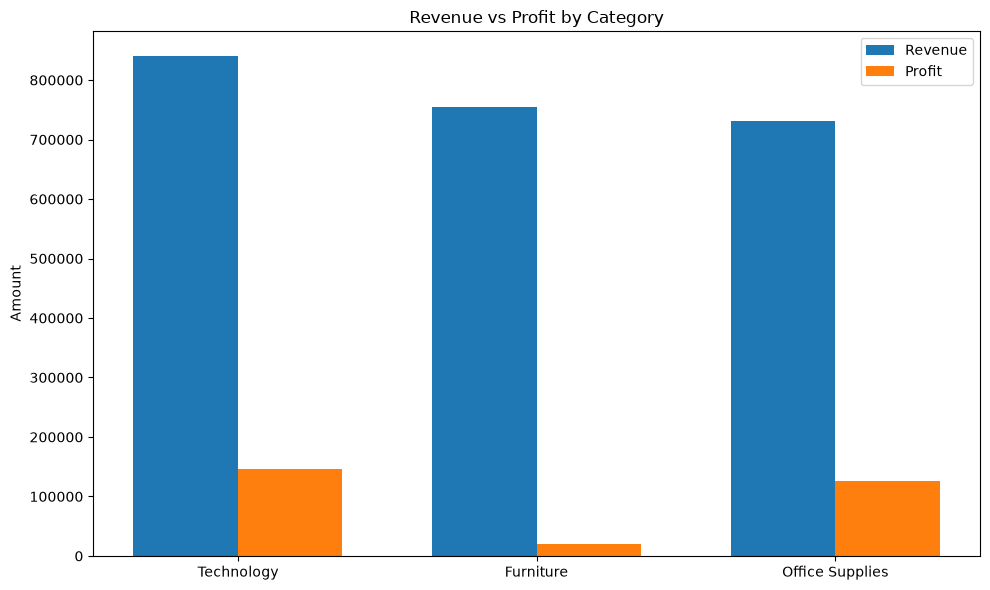

In [15]:

fig, ax = plt.subplots(figsize=(10, 6))

x = range(len(category_performance))
width = 0.35

ax.bar(
    [i - width / 2 for i in x],
    category_performance["revenue"],
    width,
    label="Revenue",
)

ax.bar(
    [i + width / 2 for i in x],
    category_performance["profit"],
    width,
    label="Profit",
)

ax.set_xticks(list(x))
ax.set_xticklabels(category_performance["category"])
ax.set_title("Revenue vs Profit by Category")
ax.set_ylabel("Amount")
ax.legend()

plt.tight_layout()
plt.show()



### Business Interpretation

- **Technology** generates the highest revenue and profit among the three categories.
- **Office Supplies** sells the largest number of units, but high sales volume does not necessarily mean the highest revenue or profit.
- **Furniture** has a comparatively low profit margin, indicating an opportunity to investigate pricing, discounting, and product-level costs.

These findings describe the observed dataset; they do not by themselves establish the causes of differences in profitability.



## 6. Regional Performance Analysis

This section compares revenue, profit, order volume, customer reach, and profit margin across the four sales regions to identify strong markets and areas for improvement.


In [16]:

regional_performance = (
    df.groupby("region", as_index=False)
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        orders=("order_id", "nunique"),
        customers=("customer_id", "nunique"),
    )
)

regional_performance["profit_margin_pct"] = (
    regional_performance["profit"]
    / regional_performance["revenue"]
    * 100
)

regional_performance = regional_performance.sort_values(
    "revenue", ascending=False
)

display(
    regional_performance.style.format({
        "revenue": "{:,.2f}",
        "profit": "{:,.2f}",
        "orders": "{:,.0f}",
        "customers": "{:,.0f}",
        "profit_margin_pct": "{:.2f}%",
    })
)


,region,revenue,profit,orders,customers,profit_margin_pct
3,West,"739,813.70","110,798.54","1,635",686,14.98%
1,East,"691,828.22","94,882.94","1,475",685,13.71%
0,Central,"503,170.62","39,865.07","1,179",629,7.92%
2,South,"391,721.90","46,749.38",822,512,11.93%


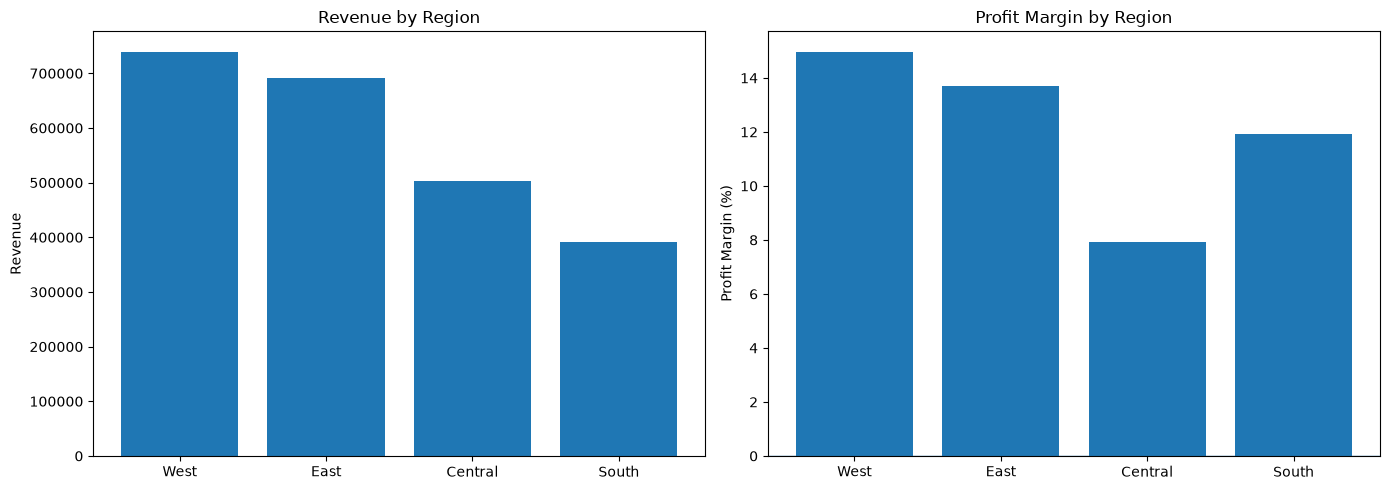

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Revenue by region
axes[0].bar(
    regional_performance["region"],
    regional_performance["revenue"],
)
axes[0].set_title("Revenue by Region")
axes[0].set_ylabel("Revenue")

# Profit margin by region
axes[1].bar(
    regional_performance["region"],
    regional_performance["profit_margin_pct"],
)
axes[1].set_title("Profit Margin by Region")
axes[1].set_ylabel("Profit Margin (%)")
axes[1].axhline(0, linewidth=1)

plt.tight_layout()
plt.show()



### Business Interpretation

- The West region leads in revenue, total profit, and profit margin.
- The East region is the second-largest contributor to revenue and profit.
- The Central region has the lowest profit margin (7.92%), suggesting that its pricing, discounting, product mix, or costs warrant further investigation.
- The South region generates less revenue than Central but more total profit, demonstrating that sales volume alone does not determine profitability.

These are descriptive findings. Further analysis is needed to determine the factors associated with regional differences.



## 7. Discount and Profitability Analysis

This section evaluates how sales revenue, profit, and profit margin vary across discount levels. It also measures the number of loss-making sales lines in each discount group.

The analysis identifies associations between discount levels and profitability; it does not establish that discounts alone caused the observed losses.


In [18]:

df["discount_group"] = pd.cut(
    df["discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 1.0],
    labels=[
        "No discount",
        "0–10%",
        "10–20%",
        "20–30%",
        "Above 30%",
    ],
    include_lowest=True,
)

discount_analysis = (
    df.groupby("discount_group", observed=False)
    .apply(
        lambda group: pd.Series({
            "sales_lines": len(group),
            "revenue": group["sales"].sum(),
            "profit": group["profit"].sum(),
            "loss_making_lines": (group["profit"] < 0).sum(),
            "profit_margin_pct": (
                group["profit"].sum()
                / group["sales"].sum() * 100
                if group["sales"].sum() else 0
            ),
        }),
        include_groups=False,
    )
    .reset_index()
)

display(
    discount_analysis.style.format({
        "sales_lines": "{:,.0f}",
        "revenue": "{:,.2f}",
        "profit": "{:,.2f}",
        "loss_making_lines": "{:,.0f}",
        "profit_margin_pct": "{:.2f}%",
    })
)


,discount_group,sales_lines,revenue,profit,loss_making_lines,profit_margin_pct
0,No discount,"4,925","1,105,323.79","326,718.05",0,29.56%
1,0–10%,96,"54,952.44","9,100.00",4,16.56%
2,10–20%,"3,758","801,497.87","92,498.88",527,11.54%
3,20–30%,230,"104,474.11","-10,513.50",211,-10.06%
4,Above 30%,"1,185","260,286.23","-125,507.50","1,159",-48.22%


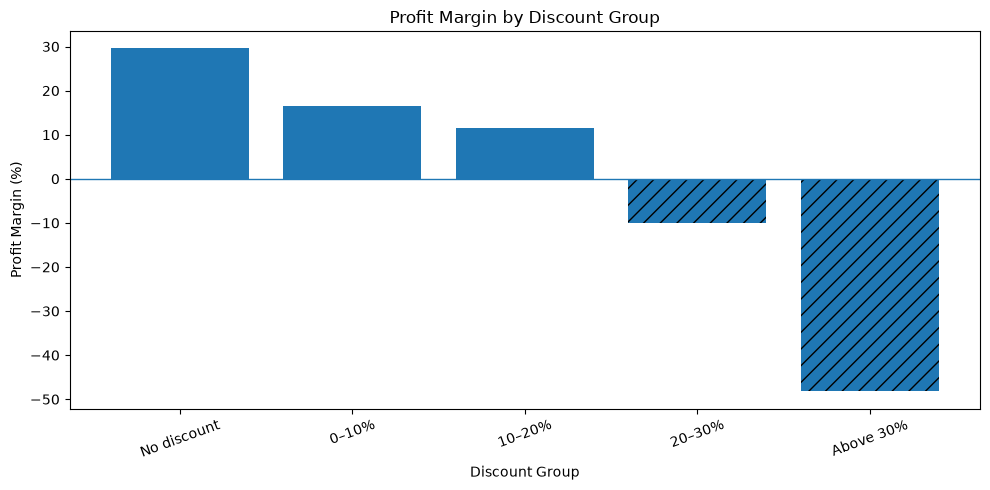

In [19]:

fig, ax = plt.subplots(figsize=(10, 5))

margins = discount_analysis["profit_margin_pct"]

bars = ax.bar(
    discount_analysis["discount_group"].astype(str),
    margins,
)

for bar, margin in zip(bars, margins):
    if margin < 0:
        bar.set_hatch("//")

ax.axhline(0, linewidth=1)
ax.set_title("Profit Margin by Discount Group")
ax.set_xlabel("Discount Group")
ax.set_ylabel("Profit Margin (%)")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()



### Business Interpretation: Discount Impact

1. **Full-price sales:** Transactions without discounts generated a 29.56% profit margin and no loss-making sales lines.
2. **Moderate discounts:** The 10–20% discount group maintained a positive margin of 11.54%, although it contained 527 loss-making lines.
3. **High discounts:** The 20–30% discount group had a negative margin of -10.06%.
4. **Very high discounts:** Discounts above 30% were associated with a -48.22% profit margin. Approximately 97.8% of sales lines in this group were loss-making.

**Recommendation:** Review high-discount transactions, establish margin-based discount approval rules, and evaluate discount performance by product subcategory and region before changing pricing policy.

**Limitation:** The analysis is descriptive. It does not establish that discounts alone caused the losses.



## 8. Subcategory Profitability Analysis

This section ranks product subcategories by profit and margin to identify loss-making products and potential opportunities to improve profitability.


In [20]:

subcategory_performance = (
    df.groupby(["category", "sub_category"], as_index=False)
    .agg(
        revenue=("sales", "sum"),
        profit=("profit", "sum"),
        units_sold=("quantity", "sum"),
        loss_making_lines=("profit", lambda values: (values < 0).sum()),
    )
)

subcategory_performance["profit_margin_pct"] = (
    subcategory_performance["profit"]
    / subcategory_performance["revenue"]
    * 100
)

subcategory_performance = subcategory_performance.sort_values(
    "profit", ascending=True
)

display(
    subcategory_performance.style.format({
        "revenue": "{:,.2f}",
        "profit": "{:,.2f}",
        "units_sold": "{:,.0f}",
        "loss_making_lines": "{:,.0f}",
        "profit_margin_pct": "{:.2f}%",
    })
)


,category,sub_category,revenue,profit,units_sold,loss_making_lines,profit_margin_pct
3,Furniture,Tables,"208,020.28","-17,753.33","1,261",205,-8.53%
0,Furniture,Bookcases,"115,361.24","-3,632.08",878,111,-3.15%
12,Office Supplies,Supplies,"46,725.48","-1,171.40",653,33,-2.51%
8,Office Supplies,Fasteners,"8,532.21","2,428.62",980,12,28.46%
15,Technology,Machines,"189,925.08","3,461.96",442,44,1.82%
9,Office Supplies,Labels,"12,695.03","5,572.71","1,410",2,43.90%
5,Office Supplies,Art,"27,659.00","6,653.22","3,092",1,24.05%
7,Office Supplies,Envelopes,"16,528.34","6,987.86",914,0,42.28%
2,Furniture,Furnishings,"95,598.08","13,891.75","3,799",178,14.53%
4,Office Supplies,Appliances,"108,213.16","18,329.48","1,750",67,16.94%


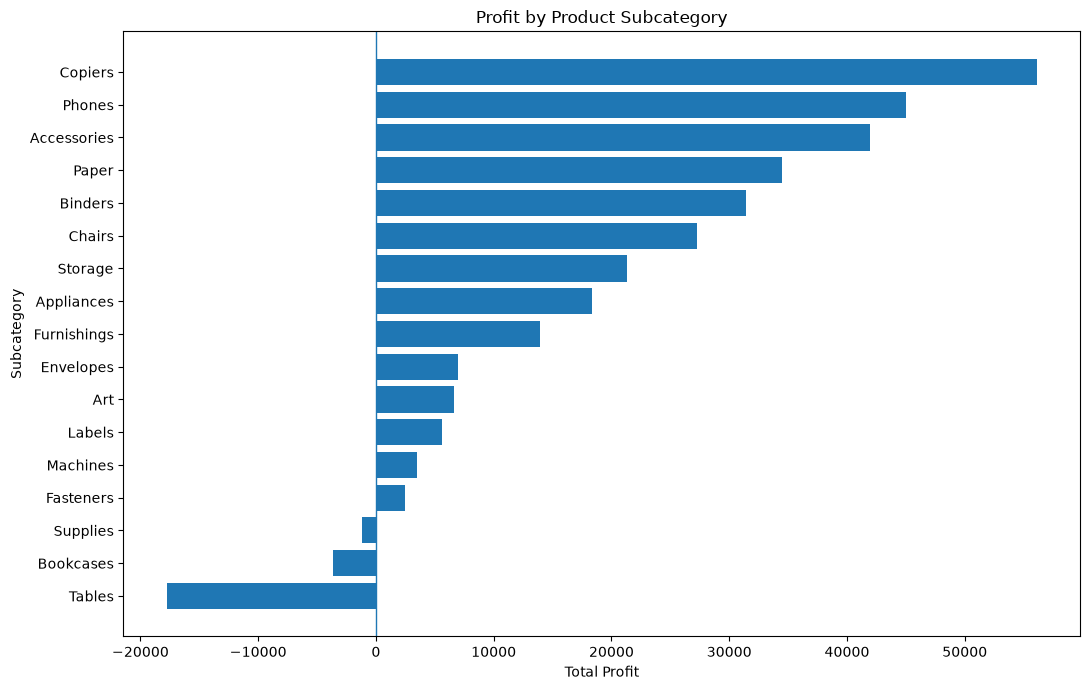

In [21]:

fig, ax = plt.subplots(figsize=(11, 7))

plot_data = subcategory_performance.sort_values("profit")

ax.barh(
    plot_data["sub_category"],
    plot_data["profit"],
)

ax.axvline(0, linewidth=1)
ax.set_title("Profit by Product Subcategory")
ax.set_xlabel("Total Profit")
ax.set_ylabel("Subcategory")

plt.tight_layout()
plt.show()



### Business Interpretation: Subcategory Profitability

1. **Tables** is the largest loss-making subcategory, with a total loss of 17,753.33 and a profit margin of -8.53%.
2. **Bookcases** and **Supplies** also report negative total profit.
3. **Copiers** is the strongest subcategory by total profit (56,093.99) and has a 37.21% profit margin.
4. **Phones** and **Accessories** are additional major contributors to total profit.
5. **Machines** has a low positive profit margin of 1.82%, making it a candidate for further review.
6. **Binders** has positive overall profit but 619 loss-making sales lines, showing that aggregate profitability can conceal individual unprofitable transactions.

### Recommendations

- Review pricing, discounts, and costs for Tables, Bookcases, and Supplies.
- Investigate low-margin Machines transactions.
- Examine loss-making Binders transactions to identify patterns in discounts, products, or regions.
- Study the practices associated with profitable subcategories to identify potentially transferable approaches.

These findings identify areas for investigation; they do not establish the causes of losses.


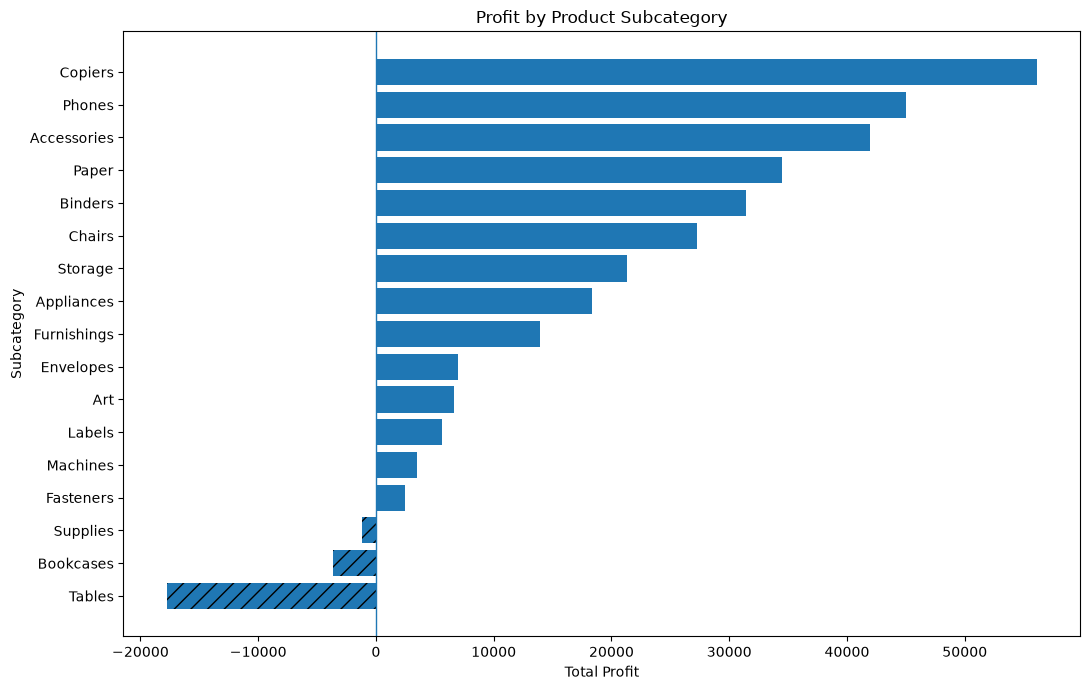

Saved subcategory_profitability.png


In [22]:

FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(11, 7))

plot_data = subcategory_performance.sort_values("profit")

bars = ax.barh(
    plot_data["sub_category"],
    plot_data["profit"],
)

for bar, value in zip(bars, plot_data["profit"]):
    if value < 0:
        bar.set_hatch("//")

ax.axvline(0, linewidth=1)
ax.set_title("Profit by Product Subcategory")
ax.set_xlabel("Total Profit")
ax.set_ylabel("Subcategory")

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "subcategory_profitability.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print("Saved subcategory_profitability.png")



## 9. Executive Summary

### Overall Performance
The dataset contains 10,194 sales records, 5,111 unique orders, and 804 unique customers. Total revenue is 2,326,534.44, with total profit of 292,295.93 and an overall profit margin of 12.56%.

### Key Findings
- **Category:** Technology generates the highest revenue and profit. Furniture has a much lower profit margin than the other categories.
- **Region:** West leads in revenue, profit, and profit margin. Central has the lowest regional profit margin.
- **Discounts:** Sales lines with discounts above 30% have a negative aggregate profit margin of -48.22%.
- **Subcategories:** Tables, Bookcases, and Supplies have negative total profit. Copiers has the highest total profit among subcategories.
- **Data quality:** No missing values or exact duplicate rows were found. Repeated order-product combinations and future-dated orders require documented review.

### Recommendations
1. Review discount approvals and monitor transaction-level profitability.
2. Investigate pricing and costs for loss-making subcategories.
3. Review the Central region's product mix and discount patterns.
4. Track both total profit and profit margin when evaluating categories and regions.

### Data Limitations
The dataset contains 989 orders dated after October 26, 2026. The origin and validity of these future-dated records should be clarified before interpreting the dataset as actual historical performance. No records were removed solely because of their dates.


In [23]:

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

category_performance.to_csv(
    OUTPUT_DIR / "category_performance_notebook.csv",
    index=False,
)

regional_performance.to_csv(
    OUTPUT_DIR / "regional_performance_notebook.csv",
    index=False,
)

discount_analysis.to_csv(
    OUTPUT_DIR / "discount_impact_notebook.csv",
    index=False,
)

subcategory_performance.to_csv(
    OUTPUT_DIR / "subcategory_profitability_notebook.csv",
    index=False,
)

print("Analysis tables exported successfully!")
print("Output directory:", OUTPUT_DIR)


Analysis tables exported successfully!
Output directory: D:\sales-performance-analysis\data\processed
